<a href="https://colab.research.google.com/github/tahzibultamim/PythonProjects/blob/sM/svm%2Cnaivebayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 9. Assignment

**Dataset:** [Diabetes Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

**Description:** The dataset contains ~100,000 patient records with 8 medical & demographic features and a binary target (`diabetes`: 0 or 1).

**Features:** `gender`, `age`, `hypertension`, `heart_disease`, `smoking_history`, `bmi`, `HbA1c_level`, `blood_glucose_level`

---

### Tasks:
1. Download the dataset from Kaggle and upload it to your Google Drive.
2. Load & preprocess the data (handle categoricals, scale features).
3. Train **SVM** and **Naive Bayes** classifiers.
4. Evaluate using **Precision, Recall, F1-Score, and ROC-AUC Curve**.
5. Create a **Results Summary Table** comparing both models.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score,classification_report)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/datasets/StudentDepressionDataset.csv')
df.head()

Mounted at /content/drive


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0



--- Support Vector Machine (SVM) Classification Report ---
              precision    recall  f1-score   support

           0       0.59      0.87      0.70       122
           1       0.20      0.05      0.08        78

    accuracy                           0.55       200
   macro avg       0.39      0.46      0.39       200
weighted avg       0.44      0.55      0.46       200


--- Naive Bayes (GaussianNB) Classification Report ---
              precision    recall  f1-score   support

           0       0.58      0.80      0.67       122
           1       0.24      0.10      0.14        78

    accuracy                           0.53       200
   macro avg       0.41      0.45      0.41       200
weighted avg       0.45      0.53      0.47       200



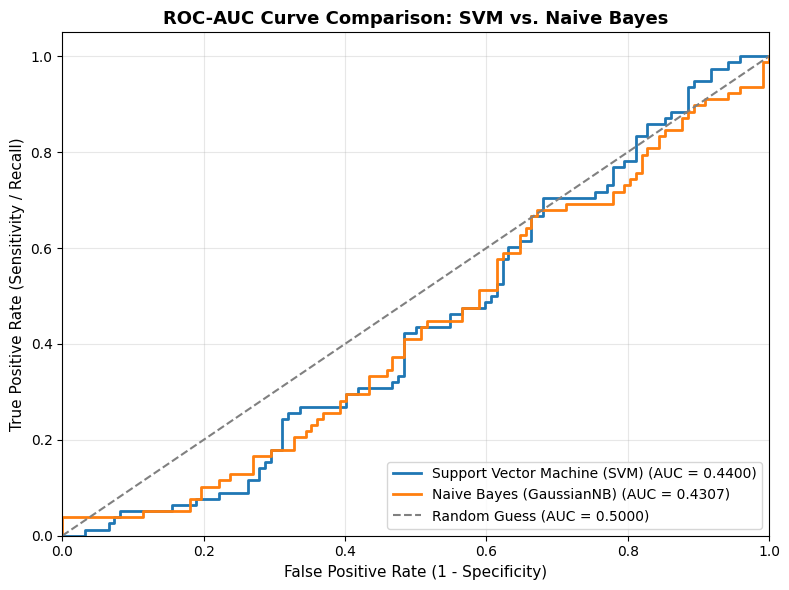


=== MODEL COMPARISON SUMMARY TABLE ===
| Model                        |   Accuracy |   Precision |   Recall |   F1-Score |   ROC-AUC |
|:-----------------------------|-----------:|------------:|---------:|-----------:|----------:|
| Support Vector Machine (SVM) |      0.55  |      0.2    |   0.0513 |     0.0816 |    0.44   |
| Naive Bayes (GaussianNB)     |      0.525 |      0.2424 |   0.1026 |     0.1441 |    0.4307 |


In [6]:
 #1. LOAD & PREPROCESS DATA
# ==========================================
# Replace this synthetic dataset block with your own file:
# df = pd.read_csv('your_dataset.csv')
# target_col = 'your_target_column'

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

np.random.seed(42)
n_samples = 1000
df = pd.DataFrame({
    'age': np.random.randint(18, 70, n_samples),
    'income': np.random.normal(60000, 15000, n_samples),
    'credit_score': np.random.normal(650, 80, n_samples),
    'education': np.random.choice(['High School', 'Bachelor', 'Master', 'PhD'], n_samples),
    'employment_type': np.random.choice(['Salaried', 'Self-Employed', 'Unemployed'], n_samples),
    'target': np.random.choice([0, 1], n_samples, p=[0.6, 0.4])
})
target_col = 'target'

# Separate features (X) and target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# Encode target variable if it is categorical/string
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)

# Automatically detect numerical and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Split BEFORE preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# sparse_output=False is required because GaussianNB only accepts dense arrays
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


# ==========================================
# 2. TRAIN SVM & NAIVE BAYES CLASSIFIERS
# ==========================================
models = {
    # probability=True is required to calculate predict_proba for ROC-AUC
    "Support Vector Machine (SVM)": SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    "Naive Bayes (GaussianNB)": GaussianNB()
}

results = []
roc_data = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train_processed, y_train)

    # Generate predictions and probabilities
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)[:, 1]

    # ==========================================
    # 3. EVALUATE METRICS
    # ==========================================
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    })

    # Store FPR and TPR for plotting the ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, roc_auc)

    print(f"\n--- {name} Classification Report ---")
    print(classification_report(y_test, y_pred, zero_division=0))


# ==========================================
# 4. PLOT ROC-AUC CURVE
# ==========================================
plt.figure(figsize=(8, 6))

for name, (fpr, tpr, roc_auc) in roc_data.items():
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
plt.title('ROC-AUC Curve Comparison: SVM vs. Naive Bayes', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 5. RESULTS SUMMARY TABLE
# ==========================================
summary_df = pd.DataFrame(results).set_index("Model")
print("\n=== MODEL COMPARISON SUMMARY TABLE ===")
print(summary_df.to_markdown())